# ZeroWaste-f: Objekterkennung mit Differenzverfahren

Dieses Notebook erkennt Abfallobjekte auf dem Förderband des **ZeroWaste-f**-Datensatzes
([Zenodo 6412647](https://zenodo.org/records/6412647)) **ohne neuronales Netz**, rein über
Differenzbildverfahren (Hintergrundsubtraktion / Frame-Differencing).

**Idee:** Die Kamera ist statisch, das Förderband hat eine relativ gleichförmige Textur. Alles,
was sich deutlich vom (geschätzten) Hintergrund oder von den Nachbar-Frames unterscheidet, ist ein
Objekt-Kandidat.

| Verfahren | Differenz zu … | Bemerkung |
|---|---|---|
| `median` | Median-Hintergrund der Sequenz | klassische Hintergrundsubtraktion |
| `framediff` | Vorgänger **und** Nachfolger (Drei-Frame-Differenz, `min(|I_t−I_{t−1}|, |I_{t+1}−I_t|)`) | unterdrückt „Geister“ |
| `mog2` | Gaussian-Mixture-Hintergrundmodell (OpenCV MOG2) | adaptiv, mit Schattenerkennung |

**Pipeline:** Differenzbild → Schwellwert → Morphologie → Zusammenhangskomponenten → Bounding Boxes
→ Bewertung gegen die COCO-Annotationen (klassenagnostisch: AP50, AP50:95, Precision/Recall).
Optional: ein kleiner Klassifikator (Farb-/Gradienten-Merkmale + Random Forest) ordnet den Kandidaten
Klassen zu und filtert Fehldetektionen.

**Erwartete Ordnerstruktur** (aus `zerowaste-f-final.zip`):
```
zerowaste-f-final/splits_final_deblurred/
├── train/  ├── data/*.PNG  └── labels.json   (COCO)
├── val/    ├── data/*.PNG  └── labels.json
└── test/   ├── data/*.PNG  └── labels.json
```
Benötigt: `numpy`, `opencv-python`, `pandas`, `matplotlib`, `scikit-learn` (optional `tqdm`).

In [1]:
import json
import re
import time
from collections import defaultdict
from itertools import product
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

try:
    from tqdm.auto import tqdm
except ImportError:  # tqdm ist optional
    def tqdm(x, **kwargs):
        return x

cv2.setNumThreads(0)
pd.set_option("display.width", 160)

## 1 Konfiguration

In [2]:
DATA_ROOT = Path("zerowaste-f-final/splits_final_deblurred")   # ggf. anpassen
SPLITS = ["train", "val", "test"]

PROC_SCALE = 0.5        # Verarbeitung in halber Auflösung (Boxen werden zurückskaliert)
BG_SAMPLES = 31         # Anzahl Frames für Median-Hintergrund / MOG2-Lernphase
MAX_FRAME_GAP = None    # Sequenz bei Lücken > MAX_FRAME_GAP Frames teilen (None = nie)
L_WEIGHT = 0.5          # Gewicht der Helligkeit (L) in der LAB-Differenz (<1 dämpft Schatten/Beleuchtung)

TUNE_MAX_IMAGES = 250   # Anzahl val-Bilder für die Parametersuche (None = alle)
RUN_CLASSIFIER = True   # optionaler Abschnitt 8
CLS_TRAIN_IMAGES = 600  # Anzahl train-Bilder für den Klassifikator

OUT_DIR = Path("zerowaste_diff_out")
OUT_DIR.mkdir(exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)

assert DATA_ROOT.exists(), f"Datenordner nicht gefunden: {DATA_ROOT.resolve()}"

## 2 Daten laden

Die Dateinamen enthalten Video-ID und Frame-Nummer (z. B. `01_frame_001290.PNG`). Daraus werden
Sequenzen gebildet – das Differenzverfahren braucht zeitlich geordnete Frames derselben Kamera.

In [3]:
def parse_name(file_name):
    """'01_frame_001290.PNG' -> ('01', 1290). Fallback: ganzer Name, Frame 0."""
    stem = Path(file_name).stem
    m = re.match(r"^(.*?)(\d+)$", stem)
    if not m:
        return stem, 0
    seq = re.sub(r"[_\-\s]*(frame)?[_\-\s]*$", "", m.group(1), flags=re.I)
    return (seq or "seq"), int(m.group(2))


def resolve_image(split_dir, file_name):
    for cand in (split_dir / "data" / file_name, split_dir / file_name,
                 split_dir / "data" / Path(file_name).name):
        if cand.exists():
            return cand
    raise FileNotFoundError(f"{file_name} nicht in {split_dir}")


def load_split(split):
    split_dir = DATA_ROOT / split
    with open(split_dir / "labels.json") as f:
        coco = json.load(f)
    categories = {c["id"]: c["name"] for c in coco["categories"]}

    gt = defaultdict(lambda: {"boxes": [], "labels": []})
    for a in coco["annotations"]:
        if a.get("iscrowd", 0):
            continue
        x, y, w, h = a["bbox"]
        if w <= 1 or h <= 1:
            continue
        gt[a["image_id"]]["boxes"].append([x, y, x + w, y + h])
        gt[a["image_id"]]["labels"].append(a["category_id"])

    rows = []
    for im in coco["images"]:
        seq, frame = parse_name(im["file_name"])
        rows.append(dict(image_id=im["id"], file=str(resolve_image(split_dir, im["file_name"])),
                         file_name=im["file_name"], seq=seq, frame=frame,
                         width=im.get("width"), height=im.get("height"),
                         n_obj=len(gt[im["id"]]["boxes"])))
    df = pd.DataFrame(rows).sort_values(["seq", "frame"]).reset_index(drop=True)

    # optional: Sequenzen an großen Frame-Lücken auftrennen
    if MAX_FRAME_GAP is not None:
        gap = df.groupby("seq")["frame"].diff().fillna(0) > MAX_FRAME_GAP
        df["seq"] = df["seq"] + "_" + gap.groupby(df["seq"]).cumsum().astype(str)

    gts = {iid: {"boxes": np.asarray(g["boxes"], np.float32).reshape(-1, 4),
                 "labels": np.asarray(g["labels"], np.int64)}
           for iid, g in gt.items()}
    for iid in df["image_id"]:
        gts.setdefault(iid, {"boxes": np.zeros((0, 4), np.float32),
                             "labels": np.zeros(0, np.int64)})
    return df, gts, categories


data = {s: load_split(s) for s in SPLITS}
CATEGORIES = data["train"][2]
print("Kategorien:", CATEGORIES)

summary = []
for s in SPLITS:
    df, gts, _ = data[s]
    gaps = df.groupby("seq")["frame"].diff().dropna()
    summary.append(dict(split=s, bilder=len(df), sequenzen=df["seq"].nunique(),
                        objekte=int(df["n_obj"].sum()), obj_pro_bild=round(df["n_obj"].mean(), 2),
                        median_frame_gap=gaps.median() if len(gaps) else np.nan))
pd.DataFrame(summary)

Kategorien: {1: 'rigid_plastic', 2: 'cardboard', 3: 'metal', 4: 'soft_plastic'}


,split,bilder,sequenzen,objekte,obj_pro_bild,median_frame_gap
0,train,3002,13,18002,6.00,100.0
1,val,572,6,3687,6.45,10.0
2,test,929,5,5077,5.47,100.0


split,test,train,val
klasse,,,
cardboard,3449,11941,2361
metal,63,259,60
rigid_plastic,315,1130,324
soft_plastic,1250,4672,942


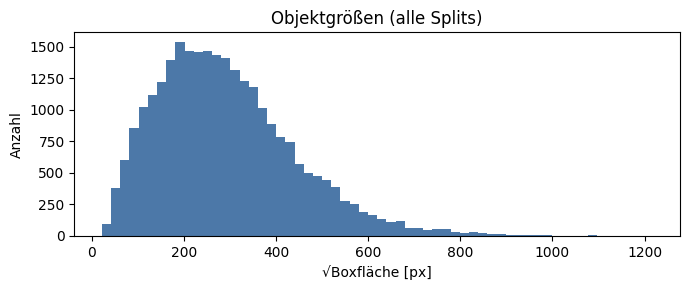

count     13.000000
mean     230.923077
std      172.900001
min        1.000000
25%      100.000000
50%      201.000000
75%      352.000000
max      501.000000
dtype: float64


In [4]:
# Klassenverteilung und Boxgrößen
rows = []
for s in SPLITS:
    for g in data[s][1].values():
        for b, l in zip(g["boxes"], g["labels"]):
            rows.append(dict(split=s, klasse=CATEGORIES.get(int(l), str(l)),
                             flaeche=float((b[2] - b[0]) * (b[3] - b[1]))))
ann_df = pd.DataFrame(rows)
display(ann_df.pivot_table(index="klasse", columns="split", values="flaeche", aggfunc="count"))

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.sqrt(ann_df["flaeche"]), bins=60, color="#4C78A8")
ax.set_xlabel("√Boxfläche [px]"); ax.set_ylabel("Anzahl"); ax.set_title("Objektgrößen (alle Splits)")
plt.tight_layout(); plt.show()

print(data["train"][0].groupby("seq").size().describe())

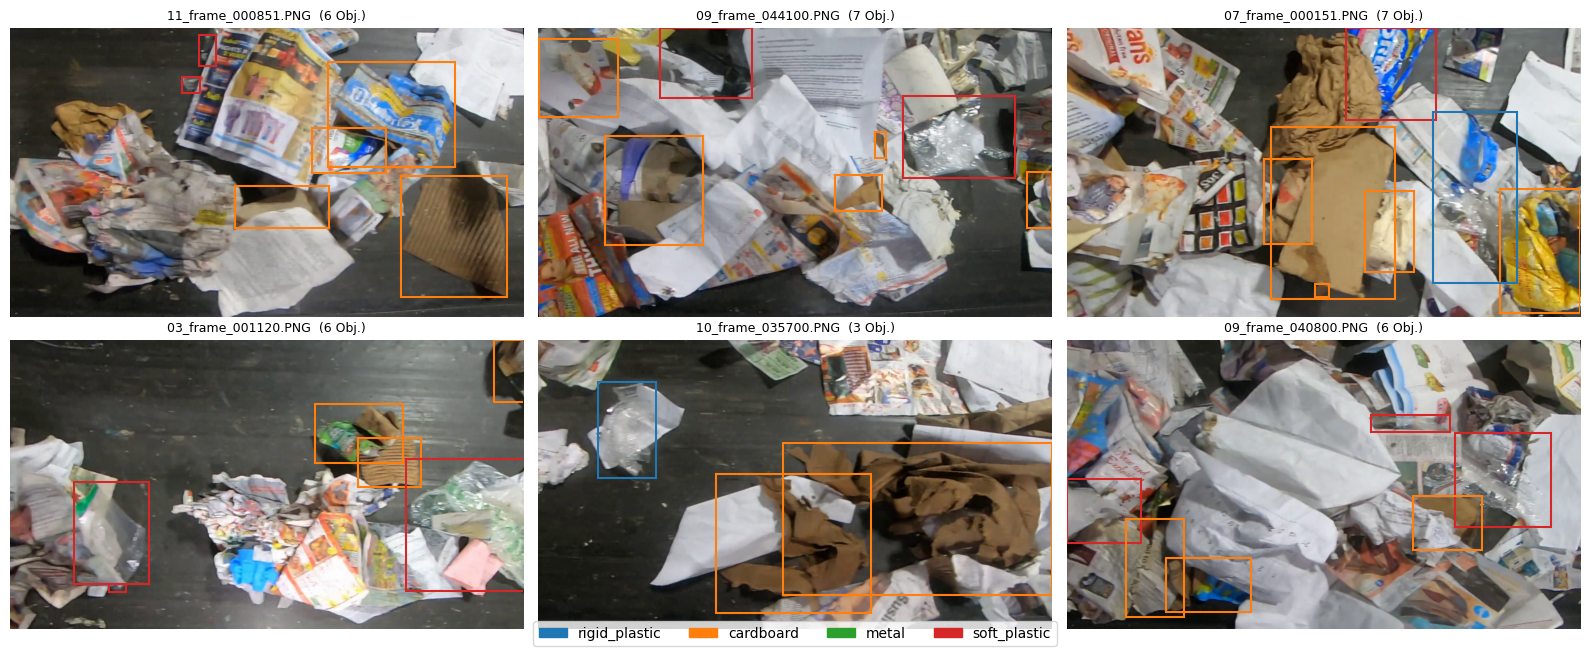

In [5]:
CLASS_COLORS = {cid: plt.cm.tab10(i % 10) for i, cid in enumerate(sorted(CATEGORIES))}


def load_img(path, scale=PROC_SCALE):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    if scale != 1:
        img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    return img


def draw_boxes(ax, boxes, labels=None, color="lime", lw=1.5, scale=1.0, ls="-"):
    for k, b in enumerate(boxes):
        x1, y1, x2, y2 = np.asarray(b) * scale
        c = CLASS_COLORS.get(int(labels[k]), color) if labels is not None else color
        ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=c, lw=lw, ls=ls))


df_tr, gt_tr, _ = data["train"]
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5))
for ax, (_, r) in zip(axes.ravel(), df_tr.sample(6, random_state=SEED).iterrows()):
    ax.imshow(cv2.cvtColor(load_img(r.file), cv2.COLOR_BGR2RGB))
    g = gt_tr[r.image_id]
    draw_boxes(ax, g["boxes"], g["labels"], scale=PROC_SCALE)
    ax.set_title(f"{r.file_name}  ({r.n_obj} Obj.)", fontsize=9); ax.axis("off")
fig.legend(handles=[mpatches.Patch(color=CLASS_COLORS[c], label=n) for c, n in CATEGORIES.items()
                    if c in CLASS_COLORS], loc="lower center", ncol=len(CATEGORIES))
plt.tight_layout(); plt.show()

## 3 Differenzbilder

Die Differenz wird im **LAB-Farbraum** berechnet (euklidischer Abstand, Helligkeit mit `L_WEIGHT`
gedämpft). So werden auch farbige Objekte mit ähnlicher Helligkeit wie das Band erkannt, während
Schatten und Beleuchtungsschwankungen weniger stark durchschlagen.

*Hinweis:* Der Median-Hintergrund bzw. das MOG2-Modell einer Test-Sequenz wird aus deren eigenen
(ungelabelten) Frames geschätzt. Es fließen dabei **keine Labels** ein – das ist beim
Differenzverfahren üblich (transduktiv), sollte aber bei Vergleichen mit Online-Verfahren beachtet werden.

In [6]:
def to_lab(img):
    return cv2.cvtColor(cv2.GaussianBlur(img, (5, 5), 0), cv2.COLOR_BGR2LAB).astype(np.float32)


def color_diff(a_lab, b_lab):
    d = a_lab - b_lab
    d[..., 0] *= L_WEIGHT
    return np.sqrt((d ** 2).sum(-1))


def to_u8(d):
    return np.clip(d, 0, 255).astype(np.uint8)


def sample_files(files, n=BG_SAMPLES):
    if len(files) <= n:
        return list(files)
    return [files[i] for i in np.linspace(0, len(files) - 1, n).round().astype(int)]


_bg_cache = {}


def median_background(key, files):
    """Pixelweiser Median über gleichmäßig verteilte Frames der Sequenz (Cache im RAM + auf Platte)."""
    if key in _bg_cache:
        return _bg_cache[key]
    path = OUT_DIR / "backgrounds" / f"{key}_{PROC_SCALE}.png"
    if path.exists():
        bg = cv2.imread(str(path))
    else:
        stack = np.stack([load_img(f) for f in sample_files(files)])
        bg = np.median(stack, axis=0).astype(np.uint8)
        path.parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(path), bg)
    _bg_cache[key] = bg
    return bg


def iter_diff_maps(df, method, split="x", mog_var=16):
    """Liefert (image_id, Bild, Differenzbild uint8) in Sequenzreihenfolge."""
    for seq, g in df.groupby("seq", sort=False):
        g = g.sort_values("frame")
        files, ids = g["file"].tolist(), g["image_id"].tolist()
        n = len(files)

        if method == "median":
            bg_lab = to_lab(median_background(f"{split}_{seq}", files))
            for iid, f in zip(ids, files):
                img = load_img(f)
                yield iid, img, to_u8(color_diff(to_lab(img), bg_lab))

        elif method == "framediff":
            labs = {}

            def get(k):
                if k not in labs:
                    img = load_img(files[k])
                    labs[k] = (img, to_lab(img))
                    for old in [j for j in labs if j < k - 1]:
                        del labs[old]
                return labs[k]

            for k in range(n):
                img, cur = get(k)
                if n == 1:
                    yield ids[k], img, np.zeros(img.shape[:2], np.uint8)
                    continue
                prev = get(k - 1)[1] if k > 0 else get(k + 1)[1]
                nxt = get(k + 1)[1] if k < n - 1 else prev
                d = np.minimum(color_diff(cur, prev), color_diff(cur, nxt))
                yield ids[k], img, to_u8(d)

        elif method == "mog2":
            sel = sample_files(files)
            mog = cv2.createBackgroundSubtractorMOG2(history=len(sel), varThreshold=mog_var,
                                                     detectShadows=True)
            for _ in range(2):                         # Lernphase (zwei Durchläufe)
                for f in sel:
                    mog.apply(cv2.GaussianBlur(load_img(f), (5, 5), 0), learningRate=-1)
            for iid, f in zip(ids, files):
                img = load_img(f)
                m = mog.apply(cv2.GaussianBlur(img, (5, 5), 0), learningRate=0)
                m[m == 127] = 0                       # Schatten verwerfen
                yield iid, img, m
        else:
            raise ValueError(method)


METHODS = ["median", "framediff", "mog2"]

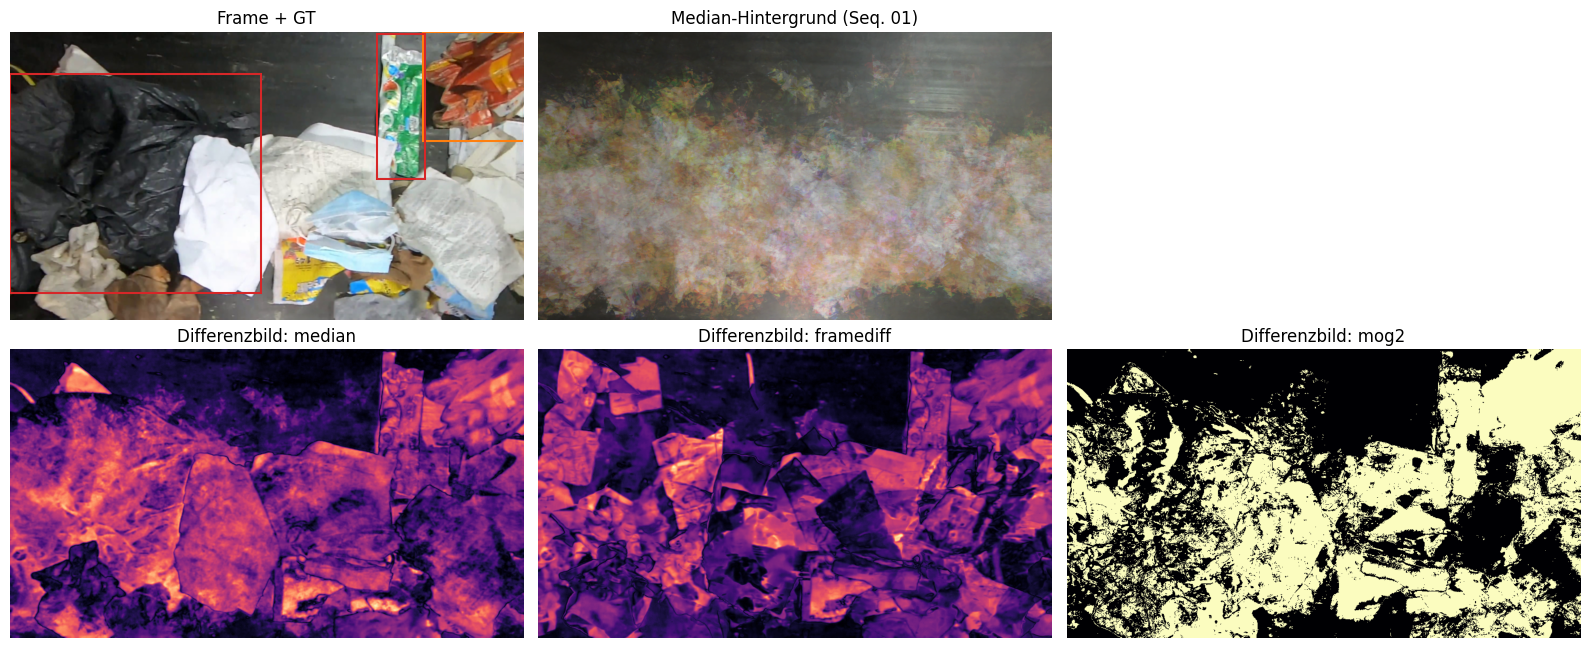

In [7]:
# Visualisierung: ein Beispiel-Frame mit allen drei Verfahren
df_va, gt_va, _ = data["val"]
seq0 = df_va["seq"].value_counts().index[0]
df_seq = df_va[df_va["seq"] == seq0]
target_id = df_seq.sort_values("frame").iloc[len(df_seq) // 2]["image_id"]

maps = {}
for m in METHODS:
    for iid, img, d in iter_diff_maps(df_seq, m, split="val"):
        if iid == target_id:
            maps[m] = d
            frame_img = img
            break

bg = median_background(f"val_{seq0}", df_seq.sort_values("frame")["file"].tolist())
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5))
axes[0, 0].imshow(cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)); axes[0, 0].set_title("Frame + GT")
draw_boxes(axes[0, 0], gt_va[target_id]["boxes"], gt_va[target_id]["labels"], scale=PROC_SCALE)
axes[0, 1].imshow(cv2.cvtColor(bg, cv2.COLOR_BGR2RGB)); axes[0, 1].set_title(f"Median-Hintergrund (Seq. {seq0})")
axes[0, 2].axis("off")
for ax, m in zip(axes[1], METHODS):
    ax.imshow(maps[m], cmap="magma"); ax.set_title(f"Differenzbild: {m}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

## 4 Vom Differenzbild zu Bounding Boxes

1. Schwellwert (fest oder Otsu)
2. Morphologie: *Opening* entfernt Rauschen, *Closing* schließt Lücken in Objekten
3. Zusammenhangskomponenten → Boxen, Filter nach Mindest-/Maximalfläche
4. Score = mittlere Differenz innerhalb der Komponente (für die AP-Berechnung)

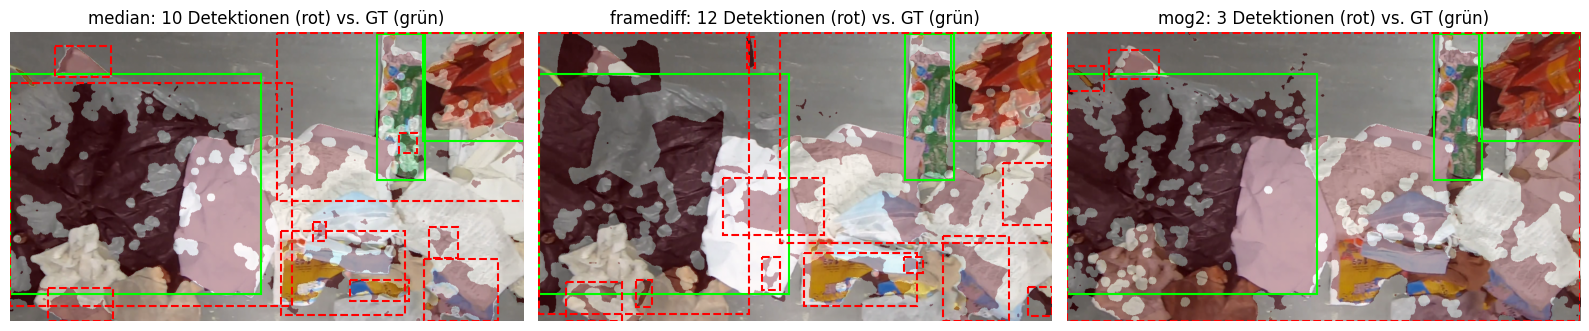

In [8]:
DEFAULT_PARAMS = dict(thr=40, open_k=3, close_k=15, min_area=1500, max_area_frac=0.6)


def _kernel(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)) if k and k > 1 else None


def detect_from_diff(d, thr=40, open_k=3, close_k=15, min_area=1500, max_area_frac=0.6,
                     return_mask=False, return_area=False):
    """Differenzbild (uint8, Verarbeitungsauflösung) -> Boxen [x1,y1,x2,y2] in Originalkoordinaten."""
    if thr == "otsu":
        _, mask = cv2.threshold(d, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        _, mask = cv2.threshold(d, thr, 255, cv2.THRESH_BINARY)
    if (k := _kernel(open_k)) is not None:
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)
    if (k := _kernel(close_k)) is not None:
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k)

    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    s2 = PROC_SCALE ** 2
    max_area = max_area_frac * mask.size
    sums = np.bincount(lab.ravel(), weights=d.ravel(), minlength=n)
    boxes, scores, areas = [], [], []
    for i in range(1, n):
        x, y, w, h, area = stats[i]
        if area < min_area * s2 or area > max_area:
            continue
        boxes.append([x, y, x + w, y + h])
        scores.append(sums[i] / area / 255.0)
        areas.append(area / s2)
    boxes = np.asarray(boxes, np.float32).reshape(-1, 4) / PROC_SCALE
    scores = np.asarray(scores, np.float32)
    if return_area:                       # Komponentenfläche in Original-Pixeln (für schnelle Rastersuche)
        return boxes, scores, np.asarray(areas, np.float32)
    return (boxes, scores, mask) if return_mask else (boxes, scores)


fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, m in zip(axes, METHODS):
    p = dict(DEFAULT_PARAMS, thr=128 if m == "mog2" else DEFAULT_PARAMS["thr"])
    b, s, mask = detect_from_diff(maps[m], **p, return_mask=True)
    ax.imshow(cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB))
    ax.imshow(mask, cmap="Reds", alpha=0.35)
    draw_boxes(ax, gt_va[target_id]["boxes"], color="lime", scale=PROC_SCALE)
    draw_boxes(ax, b, color="red", scale=PROC_SCALE, ls="--")
    ax.set_title(f"{m}: {len(b)} Detektionen (rot) vs. GT (grün)"); ax.axis("off")
plt.tight_layout(); plt.show()

## 5 Evaluation

COCO-ähnliche Average Precision (101-Punkt-Interpolation, greedy Matching nach Score).
Da das Differenzverfahren keine Klassen liefert, wird zunächst **klassenagnostisch** bewertet
(alle GT-Boxen zählen als „Objekt“).

In [9]:
def box_iou(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), np.float32)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


IOU_THRS = np.round(np.arange(0.5, 0.96, 0.05), 2)


def evaluate(preds, gt_boxes, iou_thrs=IOU_THRS):
    """preds: {iid: (boxes, scores)}, gt_boxes: {iid: boxes}. Gibt dict mit AP-Werten zurück."""
    ids = list(gt_boxes)
    n_gt = sum(len(gt_boxes[i]) for i in ids)
    entries = [(s, iid, j) for iid in ids for j, s in enumerate(preds.get(iid, (None, []))[1])]
    entries.sort(key=lambda e: -e[0])
    ious = {iid: box_iou(preds[iid][0], gt_boxes[iid]) for iid in ids if iid in preds}

    res = {}
    for t in iou_thrs:
        used = {iid: np.zeros(len(gt_boxes[iid]), bool) for iid in ids}
        tp = np.zeros(len(entries))
        for k, (_, iid, j) in enumerate(entries):
            row = ious[iid][j] if len(gt_boxes[iid]) else np.zeros(0)
            if len(row) == 0:
                continue
            row = np.where(used[iid], -1, row)
            m = int(np.argmax(row))
            if row[m] >= t:
                tp[k] = 1; used[iid][m] = True
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
        rec = ctp / max(n_gt, 1)
        prec = ctp / np.maximum(ctp + cfp, 1e-9)
        prec_env = np.maximum.accumulate(prec[::-1])[::-1] if len(prec) else prec
        ap = np.mean([prec_env[rec >= r].max() if np.any(rec >= r) else 0.0
                      for r in np.linspace(0, 1, 101)])
        res[t] = dict(ap=ap, tp=int(tp.sum()), fp=int((1 - tp).sum()), n_gt=n_gt)

    r50 = res[0.5]
    p = r50["tp"] / max(r50["tp"] + r50["fp"], 1); r = r50["tp"] / max(r50["n_gt"], 1)
    return dict(AP50=res[0.5]["ap"], AP75=res.get(0.75, {}).get("ap", np.nan),
                AP=np.mean([v["ap"] for v in res.values()]),
                P50=p, R50=r, F1_50=2 * p * r / max(p + r, 1e-9),
                n_det=len(entries), n_gt=n_gt)


def gt_box_dict(gts, ids):
    return {iid: gts[iid]["boxes"] for iid in ids}

## 6 Parametersuche auf dem Validierungs-Split

Die Differenzbilder werden pro Verfahren einmal berechnet und zwischengespeichert; anschließend
wird ein Raster aus Schwellwert, Morphologie und Mindestfläche durchsucht. Auswahlkriterium: **AP50**.

In [10]:
def subset_by_sequences(df, max_images, seed=SEED):
    """Ganze Sequenzen zufällig wählen, bis max_images erreicht (Frame-Nachbarschaft bleibt erhalten)."""
    if max_images is None or len(df) <= max_images:
        return df
    seqs = df["seq"].drop_duplicates().sample(frac=1, random_state=seed).tolist()
    keep, n = [], 0
    for s in seqs:
        keep.append(s); n += (df["seq"] == s).sum()
        if n >= max_images:
            break
    sub = df[df["seq"].isin(keep)]
    if len(sub) > 1.5 * max_images:   # wenige, sehr lange Sequenzen -> zusammenhängende Ausschnitte
        sub = pd.concat([g.sort_values("frame").head(max(1, int(max_images * len(g) / len(sub))))
                         for _, g in sub.groupby("seq")])
    return sub


df_tune = subset_by_sequences(df_va, TUNE_MAX_IMAGES)
gt_tune = gt_box_dict(gt_va, df_tune["image_id"])
print(f"Tuning auf {len(df_tune)} val-Bildern aus {df_tune['seq'].nunique()} Sequenzen")

diff_cache = {}
for m in METHODS:
    t0 = time.time()
    diff_cache[m] = {iid: d for iid, _, d in tqdm(iter_diff_maps(df_tune, m, split="val"),
                                                  total=len(df_tune), desc=m)}
    print(f"{m}: {time.time() - t0:.1f}s")

Tuning auf 257 val-Bildern aus 2 Sequenzen


median:   0%|          | 0/257 [00:00<?, ?it/s]

median: 9.8s


framediff:   0%|          | 0/257 [00:00<?, ?it/s]

framediff: 11.5s


mog2:   0%|          | 0/257 [00:00<?, ?it/s]

mog2: 16.6s


In [11]:
GRID = {
    "median":    dict(thr=[20, 30, 40, 55, 70, "otsu"], open_k=[3, 7], close_k=[9, 21, 35], min_area=[800, 2500, 6000]),
    "framediff": dict(thr=[20, 30, 40, 55, 70, "otsu"], open_k=[3, 7], close_k=[9, 21, 35], min_area=[800, 2500, 6000]),
    "mog2":      dict(thr=[128],                        open_k=[3, 7], close_k=[9, 21, 35], min_area=[800, 2500, 6000]),
}

results = []
for m in METHODS:
    g = GRID[m]
    for thr, open_k, close_k in tqdm(list(product(g["thr"], g["open_k"], g["close_k"])), desc=f"grid {m}"):
        # Segmentierung einmal je (thr, open_k, close_k); min_area wird nur noch gefiltert
        raw = {iid: detect_from_diff(d, thr=thr, open_k=open_k, close_k=close_k, min_area=0,
                                     return_area=True) for iid, d in diff_cache[m].items()}
        for min_area in g["min_area"]:
            preds = {iid: (b[a >= min_area], s[a >= min_area]) for iid, (b, s, a) in raw.items()}
            results.append(dict(method=m, thr=thr, open_k=open_k, close_k=close_k, min_area=min_area,
                                **evaluate(preds, gt_tune)))

grid_df = pd.DataFrame(results).sort_values("AP50", ascending=False)
best = {m: grid_df[grid_df["method"] == m].iloc[0] for m in METHODS}
display(grid_df.groupby("method").head(3).round(3))

BEST_PARAMS = {m: dict(DEFAULT_PARAMS, **{k: best[m][k] for k in GRID[m]}) for m in METHODS}
for m in METHODS:
    BEST_PARAMS[m]["thr"] = BEST_PARAMS[m]["thr"] if BEST_PARAMS[m]["thr"] == "otsu" else int(BEST_PARAMS[m]["thr"])
    for k in ("open_k", "close_k", "min_area"):
        BEST_PARAMS[m][k] = int(BEST_PARAMS[m][k])
BEST_METHOD = max(METHODS, key=lambda m: best[m]["AP50"])
print("Beste Parameter je Verfahren:", json.dumps(BEST_PARAMS, indent=1))
print("Bestes Verfahren (val):", BEST_METHOD)
del diff_cache

grid median:   0%|          | 0/36 [00:00<?, ?it/s]

grid framediff:   0%|          | 0/36 [00:00<?, ?it/s]

grid mog2:   0%|          | 0/6 [00:00<?, ?it/s]

,method,thr,open_k,close_k,min_area,AP50,AP75,AP,P50,R50,F1_50,n_det,n_gt
227,mog2,128,7,9,6000,0.049,0.012,0.018,0.132,0.180,0.152,2474,1810
226,mog2,128,7,9,2500,0.028,0.006,0.010,0.084,0.186,0.116,3990,1810
38,median,40,3,9,6000,0.026,0.012,0.015,0.074,0.122,0.092,2997,1810
47,median,40,7,9,6000,0.025,0.013,0.015,0.071,0.117,0.088,2986,1810
209,framediff,otsu,7,9,6000,0.024,0.011,0.014,0.086,0.151,0.109,3189,1810
37,median,40,3,9,2500,0.023,0.012,0.014,0.048,0.125,0.070,4702,1810
230,mog2,128,7,21,6000,0.022,0.004,0.008,0.110,0.093,0.101,1532,1810
128,framediff,30,3,9,6000,0.022,0.011,0.013,0.086,0.134,0.104,2830,1810
137,framediff,30,7,9,6000,0.020,0.011,0.012,0.073,0.129,0.093,3199,1810


Beste Parameter je Verfahren: {
 "median": {
  "thr": 40,
  "open_k": 3,
  "close_k": 9,
  "min_area": 6000,
  "max_area_frac": 0.6
 },
 "framediff": {
  "thr": "otsu",
  "open_k": 7,
  "close_k": 9,
  "min_area": 6000,
  "max_area_frac": 0.6
 },
 "mog2": {
  "thr": 128,
  "open_k": 7,
  "close_k": 9,
  "min_area": 6000,
  "max_area_frac": 0.6
 }
}
Bestes Verfahren (val): mog2


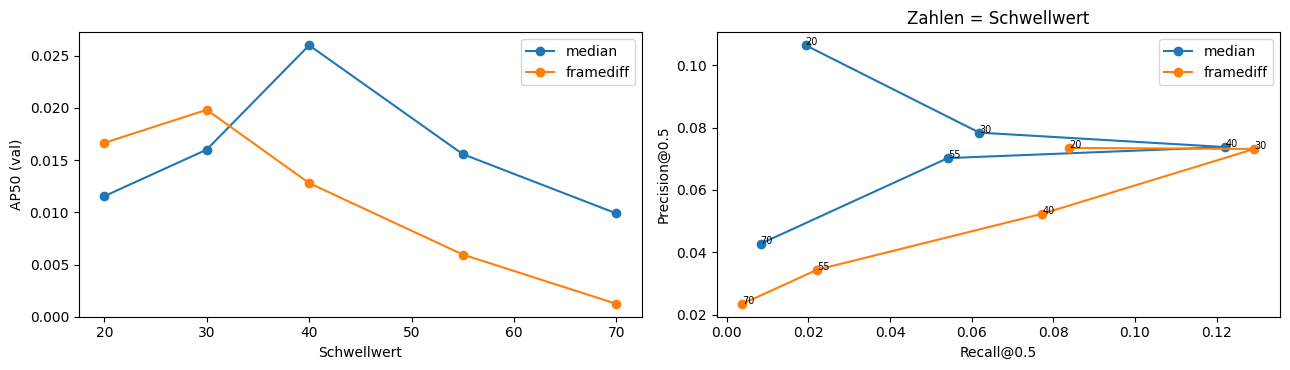

In [12]:
# Einfluss des Schwellwerts (bei sonst besten Parametern)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for m in ["median", "framediff"]:
    b = BEST_PARAMS[m]
    sel = grid_df[(grid_df.method == m) & (grid_df.open_k == b["open_k"]) &
                  (grid_df.close_k == b["close_k"]) & (grid_df.min_area == b["min_area"]) &
                  (grid_df.thr != "otsu")].copy()
    sel["thr"] = sel["thr"].astype(int); sel = sel.sort_values("thr")
    axes[0].plot(sel.thr, sel.AP50, marker="o", label=m)
    axes[1].plot(sel.R50, sel.P50, marker="o", label=m)
    for _, r in sel.iterrows():
        axes[1].annotate(str(r.thr), (r.R50, r.P50), fontsize=7)
axes[0].set_xlabel("Schwellwert"); axes[0].set_ylabel("AP50 (val)"); axes[0].legend()
axes[1].set_xlabel("Recall@0.5"); axes[1].set_ylabel("Precision@0.5"); axes[1].legend()
axes[1].set_title("Zahlen = Schwellwert")
plt.tight_layout(); plt.show()

## 7 Ergebnis auf dem Test-Split

In [13]:
def run_detector(df, method, params, split, keep_images=None, feature_fn=None):
    """Erkennung auf allen Bildern. Optional: Merkmale je Box (feature_fn) und Beispielbilder sammeln."""
    preds, feats, kept = {}, {}, {}
    p = {k: v for k, v in params.items()}
    for iid, img, d in tqdm(iter_diff_maps(df, method, split=split), total=len(df), desc=method):
        boxes, scores = detect_from_diff(d, **p)
        preds[iid] = (boxes, scores)
        if feature_fn is not None:
            feats[iid] = feature_fn(img, boxes)
        if keep_images is not None and iid in keep_images:
            kept[iid] = (img, d)
    return preds, feats, kept


df_te, gt_te, _ = data["test"]
gt_te_boxes = gt_box_dict(gt_te, df_te["image_id"])
show_ids = set(df_te.sample(4, random_state=SEED)["image_id"])

test_preds, test_rows, test_imgs = {}, [], {}
for m in METHODS:
    t0 = time.time()
    preds, _, kept = run_detector(df_te, m, BEST_PARAMS[m], "test", keep_images=show_ids)
    test_preds[m] = preds
    test_imgs[m] = kept
    test_rows.append(dict(method=m, **evaluate(preds, gt_te_boxes),
                          sec_per_img=(time.time() - t0) / len(df_te)))
test_df = pd.DataFrame(test_rows).set_index("method")
test_df.round(3)

median:   0%|          | 0/929 [00:00<?, ?it/s]

framediff:   0%|          | 0/929 [00:00<?, ?it/s]

mog2:   0%|          | 0/929 [00:00<?, ?it/s]

,AP50,AP75,AP,P50,R50,F1_50,n_det,n_gt,sec_per_img
method,,,,,,,,,
median,0.028,0.014,0.016,0.072,0.127,0.092,8982,5077,0.048
framediff,0.019,0.011,0.011,0.068,0.126,0.088,9459,5077,0.049
mog2,0.038,0.015,0.018,0.122,0.154,0.136,6437,5077,0.062


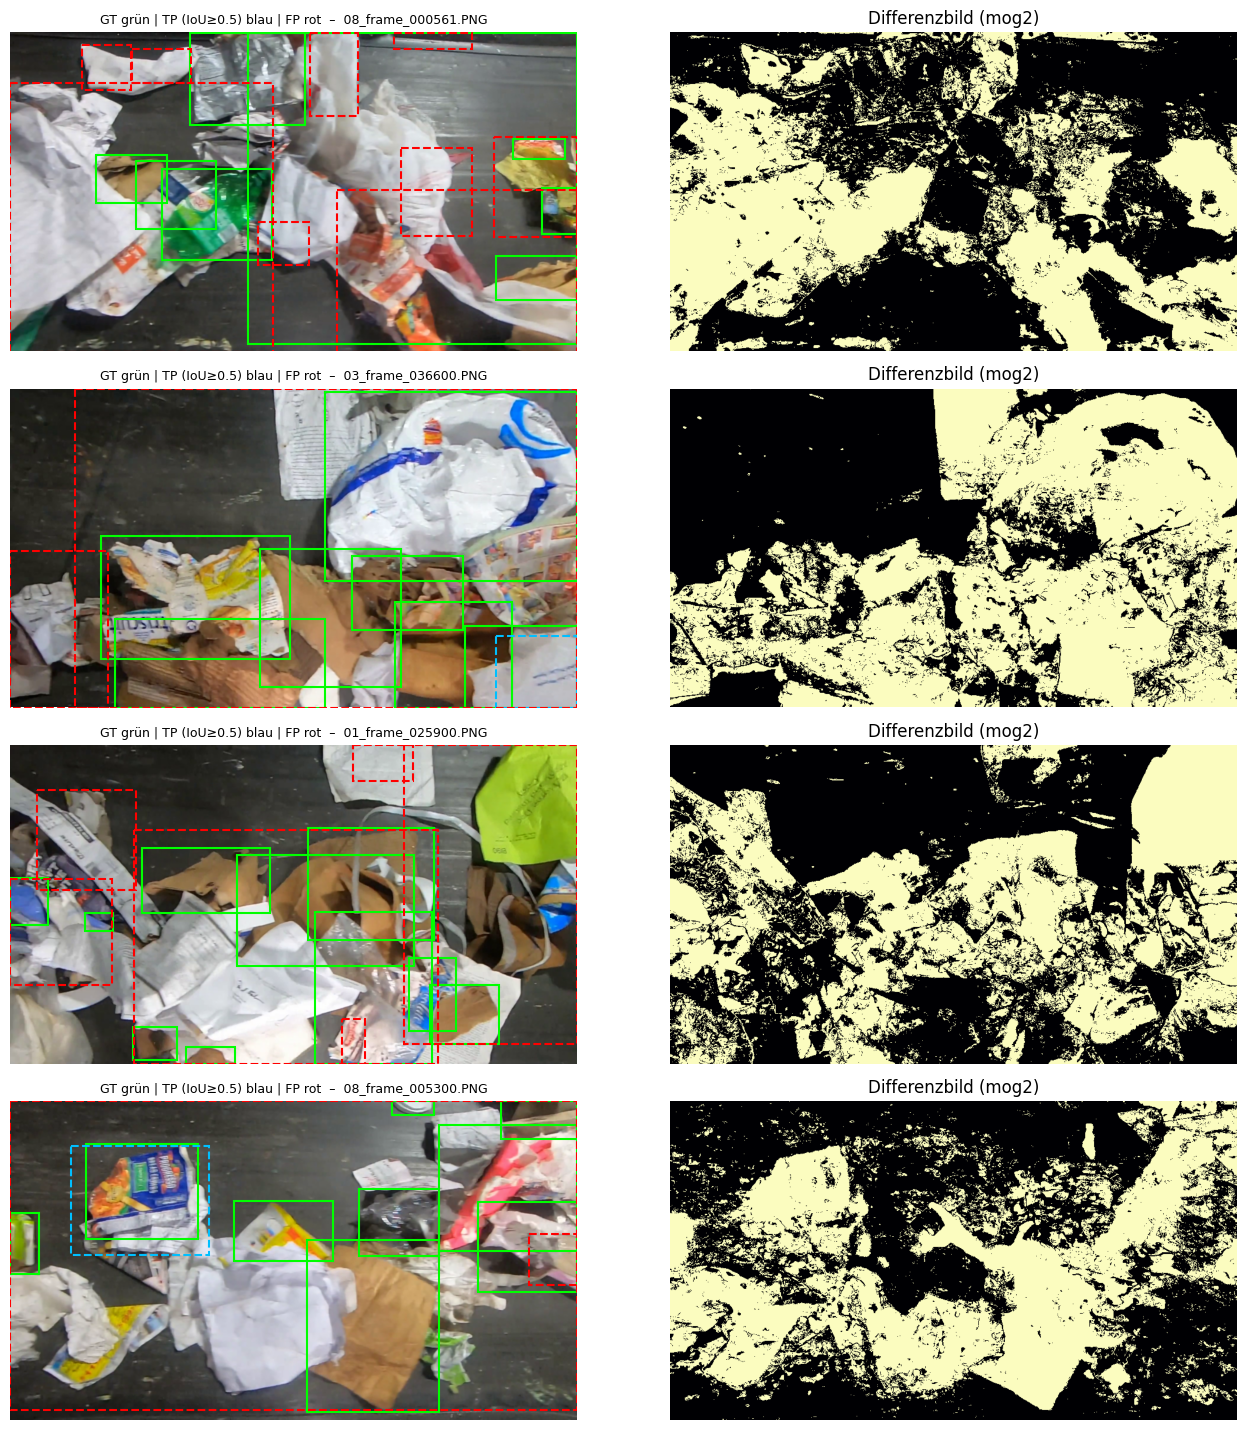

In [14]:
# Qualitative Ergebnisse des besten Verfahrens
m = BEST_METHOD
fig, axes = plt.subplots(len(show_ids), 2, figsize=(14, 3.6 * len(show_ids)))
for row, iid in zip(np.atleast_2d(axes), sorted(show_ids)):
    img, d = test_imgs[m][iid]
    boxes, scores = test_preds[m][iid]
    ious = box_iou(boxes, gt_te_boxes[iid])
    hit = ious.max(1) >= 0.5 if ious.size else np.zeros(len(boxes), bool)
    row[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    draw_boxes(row[0], gt_te_boxes[iid], color="lime", scale=PROC_SCALE)
    draw_boxes(row[0], boxes[hit], color="deepskyblue", scale=PROC_SCALE, ls="--")
    draw_boxes(row[0], boxes[~hit], color="red", scale=PROC_SCALE, ls="--")
    row[0].set_title(f"GT grün | TP (IoU≥0.5) blau | FP rot  –  {df_te.set_index('image_id').loc[iid, 'file_name']}",
                     fontsize=9)
    row[1].imshow(d, cmap="magma"); row[1].set_title(f"Differenzbild ({m})")
    for ax in row:
        ax.axis("off")
plt.tight_layout(); plt.show()

In [15]:
# Recall nach Objektgröße und Klasse (IoU ≥ 0.5) – wo versagt das Differenzverfahren?
rows = []
for iid in df_te["image_id"]:
    g = gt_te[iid]
    if not len(g["boxes"]):
        continue
    ious = box_iou(test_preds[BEST_METHOD][iid][0], g["boxes"])
    found = ious.max(0) >= 0.5 if ious.size else np.zeros(len(g["boxes"]), bool)
    for b, l, f in zip(g["boxes"], g["labels"], found):
        area = (b[2] - b[0]) * (b[3] - b[1])
        rows.append(dict(klasse=CATEGORIES.get(int(l), str(l)), gefunden=f,
                         groesse=pd.cut([area], [0, 32**2, 96**2, 256**2, np.inf],
                                        labels=["<32²", "32²–96²", "96²–256²", ">256²"])[0]))
rec_df = pd.DataFrame(rows)
display(rec_df.groupby("klasse")["gefunden"].agg(["mean", "count"]).rename(columns={"mean": "recall"}).round(3))
display(rec_df.groupby("groesse", observed=True)["gefunden"].agg(["mean", "count"])
        .rename(columns={"mean": "recall"}).round(3))

,recall,count
klasse,,
cardboard,0.157,3449
metal,0.127,63
rigid_plastic,0.232,315
soft_plastic,0.130,1250


,recall,count
groesse,,
32²–96²,0.016,245
96²–256²,0.133,1871
<32²,0.000,4
>256²,0.180,2957


## 8 (Optional) Klassifikation der Kandidaten

Das Differenzverfahren liefert nur „Objekt / kein Objekt“. Ein leichter Klassifikator auf
handgefertigten Merkmalen (HSV-Histogramm, Gradientenorientierung, Textur, Geometrie) ordnet jeder
Box eine ZeroWaste-Klasse **oder „Hintergrund“** zu. Trainiert wird auf Detektionen des besten
Verfahrens auf Trainingsbildern (IoU ≥ 0.5 → Klasse des GT-Objekts, IoU < 0.3 → Hintergrund)
plus den GT-Boxen selbst.

Damit lassen sich (a) Fehldetektionen herausfiltern (klassenagnostisch neu bewerten) und
(b) klassenbezogene AP50-Werte berechnen.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report


def crop_features(img, boxes):
    """Merkmale je Box; img in Verarbeitungsauflösung, Boxen in Originalkoordinaten."""
    H, W = img.shape[:2]
    out = []
    for b in np.asarray(boxes).reshape(-1, 4):
        x1, y1, x2, y2 = (b * PROC_SCALE).round().astype(int)
        x1, y1 = np.clip([x1, y1], 0, [W - 1, H - 1]); x2, y2 = np.clip([x2, y2], [x1 + 2, y1 + 2], [W, H])
        crop = img[y1:y2, x1:x2]
        hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
        h = cv2.calcHist([hsv], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256]).ravel()
        h /= h.sum() + 1e-6
        gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY).astype(np.float32)
        gx, gy = cv2.Sobel(gray, cv2.CV_32F, 1, 0), cv2.Sobel(gray, cv2.CV_32F, 0, 1)
        mag, ang = cv2.cartToPolar(gx, gy, angleInDegrees=True)
        oh, _ = np.histogram(ang % 180, bins=9, range=(0, 180), weights=mag)
        oh = oh / (oh.sum() + 1e-6)
        lap = cv2.Laplacian(gray, cv2.CV_32F)
        bw, bh = (b[2] - b[0]), (b[3] - b[1])
        stats = [gray.mean() / 255, gray.std() / 255, mag.mean() / 255, np.abs(lap).mean() / 255,
                 hsv[..., 1].mean() / 255, hsv[..., 1].std() / 255, hsv[..., 2].std() / 255,
                 np.log1p(bw * bh), bw / max(bh, 1), (b[0] + b[2]) / 2 / (W / PROC_SCALE),
                 (b[1] + b[3]) / 2 / (H / PROC_SCALE)]
        out.append(np.concatenate([h, oh, stats]).astype(np.float32))

    n_feat = 8 * 4 * 4 + 9 + 11          # HSV-Histogramm + Orientierungen + Statistik/Geometrie
    if not out:                           # keine Boxen im Bild
        return np.zeros((0, n_feat), np.float32)
    return np.stack(out).astype(np.float32)


def label_proposals(boxes, gt, pos=0.5, neg=0.3):
    """-1 = ignorieren, 0 = Hintergrund, sonst category_id."""
    if len(boxes) == 0:
        return np.zeros(0, np.int64)
    if len(gt["boxes"]) == 0:
        return np.zeros(len(boxes), np.int64)
    ious = box_iou(boxes, gt["boxes"])
    best, arg = ious.max(1), ious.argmax(1)
    lab = np.where(best >= pos, gt["labels"][arg], np.where(best < neg, 0, -1))
    return lab.astype(np.int64)


if RUN_CLASSIFIER:
    BG_ID = 0 if 0 not in CATEGORIES else -100
    df_cls = subset_by_sequences(df_tr, CLS_TRAIN_IMAGES)
    preds_tr, feats_tr, _ = run_detector(df_cls, BEST_METHOD, BEST_PARAMS[BEST_METHOD], "train",
                                         feature_fn=crop_features)
    X, y = [], []
    gt_imgs = set(df_cls.sample(min(len(df_cls), 300), random_state=SEED)["image_id"])
    file_of = df_tr.set_index("image_id")["file"]
    for iid in df_cls["image_id"]:
        lab = label_proposals(preds_tr[iid][0], gt_tr[iid])
        lab = np.where(lab == 0, BG_ID, lab)
        keep = lab != -1
        X.append(feats_tr[iid][keep]); y.append(lab[keep])
        if iid in gt_imgs and len(gt_tr[iid]["boxes"]):       # GT-Boxen als zusätzliche Positivbeispiele
            X.append(crop_features(load_img(file_of[iid]), gt_tr[iid]["boxes"]))
            y.append(gt_tr[iid]["labels"])
    X, y = np.concatenate(X), np.concatenate(y)
    names = {**CATEGORIES, BG_ID: "hintergrund"}
    print("Trainingsbeispiele:", pd.Series(y).map(names).value_counts().to_dict())

    clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
                                 n_jobs=-1, random_state=SEED)
    clf.fit(X, y)

mog2:   0%|          | 0/601 [00:00<?, ?it/s]

Trainingsbeispiele: {'hintergrund': 5396, 'cardboard': 1907, 'soft_plastic': 562, 'rigid_plastic': 107, 'metal': 24}


In [23]:
if RUN_CLASSIFIER:
    # Merkmale der Test-Detektionen (Bilder werden erneut gelesen; Differenzbild wird nicht benötigt)
    file_of_te = df_te.set_index("image_id")["file"]
    classes = clf.classes_
    bg_col = int(np.where(classes == BG_ID)[0][0]) if BG_ID in classes else None
    cls_preds, agn_rescored, Xte, yte = {}, {}, [], []
    for iid in tqdm(df_te["image_id"], desc="Klassifikation"):
        boxes, scores = test_preds[BEST_METHOD][iid]
        if len(boxes) == 0:
            cls_preds[iid] = (boxes, scores, np.zeros(0, np.int64), np.zeros((0, len(classes))))
            agn_rescored[iid] = (boxes, scores)
            continue
        f = crop_features(load_img(file_of_te[iid]), boxes)
        proba = clf.predict_proba(f)
        p_obj = 1 - proba[:, bg_col] if bg_col is not None else np.ones(len(boxes))
        fg = proba.copy()
        if bg_col is not None:
            fg[:, bg_col] = -1
        cls_preds[iid] = (boxes, scores, classes[fg.argmax(1)], proba)
        agn_rescored[iid] = (boxes, p_obj.astype(np.float32))
        lab = label_proposals(boxes, gt_te[iid]); lab = np.where(lab == 0, BG_ID, lab)
        Xte.append(f[lab != -1]); yte.append(lab[lab != -1])

    print(classification_report(np.concatenate(yte), clf.predict(np.concatenate(Xte)),
                                labels=list(classes), target_names=[names[c] for c in classes],
                                zero_division=0))

    # (a) klassenagnostisch: Score = P(Objekt) statt mittlerer Differenz
    agn = pd.DataFrame([dict(variante=f"{BEST_METHOD} (Differenz-Score)", **evaluate(test_preds[BEST_METHOD], gt_te_boxes)),
                        dict(variante=f"{BEST_METHOD} + Klassifikator-Score", **evaluate(agn_rescored, gt_te_boxes))])
    display(agn.set_index("variante").round(3))

    # (b) klassenbezogene AP50 / AP
    per_class = []
    for cid, cname in CATEGORIES.items():
        gts_c = {iid: gt_te[iid]["boxes"][gt_te[iid]["labels"] == cid] for iid in df_te["image_id"]}
        if sum(len(v) for v in gts_c.values()) == 0:
            continue
        col = int(np.where(classes == cid)[0][0]) if cid in classes else None
        preds_c = {}
        for iid, (boxes, _, lab, proba) in cls_preds.items():
            sel = lab == cid
            preds_c[iid] = (boxes[sel], proba[sel, col] if col is not None else np.zeros(sel.sum()))
        r = evaluate(preds_c, gts_c)
        per_class.append(dict(klasse=cname, AP50=r["AP50"], AP=r["AP"], R50=r["R50"], n_gt=r["n_gt"]))
    per_class = pd.DataFrame(per_class).set_index("klasse")
    per_class.loc["mAP"] = per_class[["AP50", "AP", "R50"]].mean()
    display(per_class.round(3))

Klassifikation:   0%|          | 0/929 [00:00<?, ?it/s]

               precision    recall  f1-score   support

  hintergrund       0.91      0.92      0.92      4978
rigid_plastic       0.00      0.00      0.00        73
    cardboard       0.41      0.51      0.45       541
        metal       0.00      0.00      0.00         8
 soft_plastic       0.17      0.01      0.01       161

     accuracy                           0.85      5761
    macro avg       0.30      0.29      0.28      5761
 weighted avg       0.83      0.85      0.83      5761



,AP50,AP75,AP,P50,R50,F1_50,n_det,n_gt
variante,,,,,,,,
mog2 (Differenz-Score),0.038,0.015,0.018,0.122,0.154,0.136,6437,5077
mog2 + Klassifikator-Score,0.055,0.017,0.022,0.122,0.154,0.136,6437,5077


,AP50,AP,R50,n_gt
klasse,,,,
rigid_plastic,0.000,0.000,0.000,315.0
cardboard,0.056,0.021,0.153,3449.0
metal,0.000,0.000,0.000,63.0
soft_plastic,0.005,0.003,0.045,1250.0
mAP,0.015,0.006,0.050,NaN


In [ ]:
# Beispiel-Bounding-Boxes: GT vs. Detektionen mit Klasse und Score
N_SHOW = 6           # Anzahl Bilder
MIN_P_OBJ = 0.5      # nur Boxen mit P(Objekt) >= Schwelle zeigen (None = alle)
ONLY_WITH_GT = True  # nur Bilder mit mindestens einem GT-Objekt

cand = df_te[df_te["n_obj"] > 0] if ONLY_WITH_GT else df_te
show = cand.sample(min(N_SHOW, len(cand)), random_state=None)   # random_state=SEED für feste Auswahl
names = {**CATEGORIES, BG_ID: "hintergrund"} if RUN_CLASSIFIER else CATEGORIES

fig, axes = plt.subplots(len(show), 2, figsize=(18, 5 * len(show)), squeeze=False)
for row, (_, r) in zip(axes, show.iterrows()):
    iid = r.image_id
    img = cv2.cvtColor(load_img(r.file), cv2.COLOR_BGR2RGB)
    g = gt_te[iid]

    # links: Ground Truth
    row[0].imshow(img)
    draw_boxes(row[0], g["boxes"], g["labels"], scale=PROC_SCALE, lw=2)
    for b, l in zip(g["boxes"], g["labels"]):
        row[0].text(b[0] * PROC_SCALE, b[1] * PROC_SCALE - 3, CATEGORIES.get(int(l), l), fontsize=8,
                    color="white", bbox=dict(fc=CLASS_COLORS.get(int(l), "gray"), ec="none", pad=1))
    row[0].set_title(f"Ground Truth – {r.file_name} ({len(g['boxes'])} Obj.)", fontsize=10)

    # rechts: Detektionen
    row[1].imshow(img)
    if RUN_CLASSIFIER:
        boxes, scores, labels, proba = cls_preds[iid]
        p_obj = agn_rescored[iid][1]
        keep = p_obj >= MIN_P_OBJ if MIN_P_OBJ is not None else np.ones(len(boxes), bool)
        conf = proba[np.arange(len(labels)), np.searchsorted(classes, labels)] if len(boxes) else []
    else:
        boxes, scores = test_preds[BEST_METHOD][iid]
        labels, conf, keep = np.full(len(boxes), -1), scores, np.ones(len(boxes), bool)

    ious = box_iou(boxes, g["boxes"])
    for k in np.where(keep)[0]:
        b = boxes[k]
        hit = ious.size and ious[k].max() >= 0.5
        right = hit and RUN_CLASSIFIER and g["labels"][ious[k].argmax()] == labels[k]
        c = CLASS_COLORS.get(int(labels[k]), "red")
        x1, y1, x2, y2 = b * PROC_SCALE
        row[1].add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=c, lw=2,
                                            ls="-" if hit else "--"))
        txt = f"{names.get(int(labels[k]), 'Objekt')} {conf[k]:.2f}" + (" ✓" if right else "")
        row[1].text(x1, y1 - 3, txt, fontsize=8, color="white", bbox=dict(fc=c, ec="none", pad=1))
    row[1].set_title(f"Detektionen ({BEST_METHOD}{' + Klassifikator' if RUN_CLASSIFIER else ''}): "
                     f"{keep.sum()} Boxen | durchgezogen = IoU≥0.5, gestrichelt = Fehldetektion, ✓ = Klasse richtig",
                     fontsize=10)
    for ax in row:
        ax.axis("off")

fig.legend(handles=[mpatches.Patch(color=CLASS_COLORS[c], label=n) for c, n in CATEGORIES.items()
                    if c in CLASS_COLORS], loc="upper center", ncol=len(CATEGORIES), bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.98)); plt.savefig(OUT_DIR / "beispiele_test.png", dpi=110); plt.show()

## 9 Export & Zusammenfassung

In [24]:
# Detektionen im COCO-Ergebnisformat speichern (z. B. für pycocotools)
coco_results = []
use_cls = RUN_CLASSIFIER
for iid in df_te["image_id"]:
    if use_cls:
        boxes, _, lab, proba = cls_preds[iid]
        sc = proba[np.arange(len(lab)), np.searchsorted(classes, lab)] if len(boxes) else []
    else:
        boxes, sc = test_preds[BEST_METHOD][iid]
        lab = np.full(len(boxes), min(CATEGORIES))
    for b, l, s in zip(boxes, lab, sc):
        coco_results.append(dict(image_id=int(iid), category_id=int(l), score=float(s),
                                 bbox=[float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])]))
with open(OUT_DIR / f"test_detections_{BEST_METHOD}.json", "w") as f:
    json.dump(coco_results, f)
with open(OUT_DIR / "best_params.json", "w") as f:
    json.dump(dict(best_method=BEST_METHOD, params=BEST_PARAMS, proc_scale=PROC_SCALE,
                   l_weight=L_WEIGHT), f, indent=2)
grid_df.to_csv(OUT_DIR / "grid_val.csv", index=False)
test_df.to_csv(OUT_DIR / "results_test.csv")

print(f"{len(coco_results)} Detektionen gespeichert in {OUT_DIR.resolve()}")
test_df[["AP50", "AP75", "AP", "P50", "R50", "F1_50", "sec_per_img"]].round(3)

6437 Detektionen gespeichert in /mnt/NVME/bjoern/ZEROWASTE-WESORT.AI/zerowaste_diff_out


,AP50,AP75,AP,P50,R50,F1_50,sec_per_img
method,,,,,,,
median,0.028,0.014,0.016,0.072,0.127,0.092,0.048
framediff,0.019,0.011,0.011,0.068,0.126,0.088,0.049
mog2,0.038,0.015,0.018,0.122,0.154,0.136,0.062


### Einordnung

- **Stärken:** kein Training für die Lokalisierung nötig, schnell, interpretierbar; gut geeignet als
  Baseline oder als Region-Proposal-Stufe vor einem Klassifikator.
- **Grenzen:**
  - Sich berührende oder überlappende Objekte verschmelzen zu einer Komponente (eine Box für mehrere
    Objekte → niedrige AP bei hohen IoU-Schwellen).
  - Transparente Folien (`soft_plastic`) und bandfarbene Kartonagen erzeugen kaum Differenz.
  - Ist das Band dicht belegt, enthält der Median-Hintergrund selbst Objekte; die Drei-Frame-Differenz
    ist davon unabhängig, braucht aber genügend Bewegung zwischen den Frames.
  - Beleuchtungswechsel/Schatten → `L_WEIGHT` und MOG2-Schattenerkennung helfen nur teilweise.
- **Ideen:** Watershed/Distanztransformation zum Trennen verschmolzener Objekte, ROI-Maske auf das
  Band, Bewegungskompensation (Bandvorschub schätzen und Vorgänger-Frame verschieben), oder die
  Kandidaten als Proposals für ein CNN verwenden.